# Lennard-Jones Potential

The example below illustrates how to perform molecular dynamics simulations with the `Amardus MD engine` using Lennard-Jones potential.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
from ase import Atoms as AseAtoms
from ase.build import bulk
from ase.md.velocitydistribution import (
    MaxwellBoltzmannDistribution,
    Stationary,
)
from amardus import BANNER, Atoms, System, Simulation
from amardus.parameters import get_default_unit
from amardus.reporters import StateReporter, XyzReporter, CSVReporter
from amardus.integration import VerletIntegrator
from amardus.coupling import BrendsenThermostat, BrendsenBarostat
from amardus.potentials import LennardJonesPotential, LennardJonesParams

In [10]:
plt.style.use('fivethirtyeight') # fivethirtyeight is name of style

## Preparing simulation

In [2]:
unit = get_default_unit()
time_step = 0.001 * unit.picoseconds
cutoff = 7.0 * unit.angstrom
temperature = 300.0 * unit.kelvin
pressure = 1.0 * unit.bar
thermostat_coupling_time = 10 * time_step
barostat_coupling_time = 10 * time_step
# ewald_alpha=3.5 / cutoff
# ewald_kmax=2

atoms_ase: AseAtoms = bulk("Ar", "fcc", a=5.385, cubic=True).repeat((6, 6, 6))
MaxwellBoltzmannDistribution(
    atoms_ase,
    temperature_K=temperature / unit.kelvin,
    rng=np.random.default_rng(1234),
)
Stationary(atoms_ase)
atom_types_map = {"Ar": 0}
atoms = Atoms.from_ase(atoms_ase, atom_types_map)

lennard_jones = LennardJonesPotential(
    cutoff_radius=cutoff,
    params=LennardJonesParams.from_list(
        epsilon=[e * unit.electronvolt for e in [0.01032]],
        sigma=[s * unit.angstrom for s in [3.405]],
    ),
)

system = System.create(
    atoms,
    neighbor_cutoff=cutoff,
    neighbor_skin=2.0 * unit.angstrom,
    neighbor_max_atoms=300,
)

thermostat = BrendsenThermostat(temperature, thermostat_coupling_time)
barostat = BrendsenBarostat(
    pressure,
    barostat_coupling_time,
    interval=1,
    compressibility=1.0 / (1e4 * unit.bar),
)
verlet = VerletIntegrator(
    time_step=time_step,
    system_couplings=[
        thermostat,
        barostat,
    ],
)


state = StateReporter(interval=10_000, normalize=False)
xyz = XyzReporter("ar.xyz", atom_types_map, interval=1000)
csv = CSVReporter("thermo-ar.csv", interval=1000, ignore_first_steps=10_000)

simulation = Simulation(
    system,
    verlet,
    forcefields=[lennard_jones],
    reporters=[state, xyz, csv],
)
print(BANNER)
print(simulation)


      _                            _
     / \   _ __ ___   __ _ _ __ __| |_   _ ___
    / _ \ | '_ ` _ \ / _` | '__/ _` | | | / __|
   / ___ \| | | | | | (_| | | | (_| | |_| \__ \
  /_/   \_\_| |_| |_|\__,_|_|  \__,_|\__,_|___/
           Molecular Dynamics Engine
-------------------------------------------------
Simulation(system=System(num_atoms=864), integrator=VerletIntegrator(time_step=0.0982269, system_couplings=[BrendsenThermostat(target_temperature=300.0, coupling_time=0.9822690000000001, interval=1), BrendsenBarostat(target_pressure=6.2415e-07, coupling_time=0.9822690000000001, compressibility=160.21789633902108, interval=1)]), forcefields=[LennardJonesPotential(cutoff_radius=7.0)], reporters=[StateReporter(interval=10000), XyzReporter(interval=1000), CSVReporter(interval=1000)], energy_minimizer=GradientDescentEnergyMinimizer(max_steps=10000, force_tolerance=0.001, step_size=0.005))


## Performing simulations

### Equilibration simulation (NPT)

Run the benchmark LAMMPS script using the following command:
```bash
pixi run lmp < in.lj
```

In [3]:
simulation.minimize_energy()

Energy minimization converged after 2471 steps.


In [4]:
simulation.step(400_000)

Step     Temp           Press          PotEng         KinEng         TotEng         AvgNgh         Density       
0        309.48533852   35.45438965    -67.26142537   34.56355945    -32.69786592   74.99305556    1.69921003    
10000    300.00544188   11.08876096    -0.59588398    33.50483734    32.90895336    0.85416667     0.01790397    
20000    299.96816382   5.72334161     -0.19029677    33.50067410    33.31037733    0.40740741     0.00909146    
30000    300.00451273   3.91219101     -0.18853289    33.50473357    33.31620068    0.29166667     0.00629083    
40000    300.02082308   3.07572516     -0.19658381    33.50655512    33.30997131    0.20601852     0.00491997    
50000    299.98965243   2.55194994     -0.16427782    33.50307396    33.33879614    0.21064815     0.00410833    
60000    299.98784037   2.22518124     -0.06329250    33.50287159    33.43957909    0.14120370     0.00357476    
70000    300.00333965   1.98651851     -0.10136201    33.50460256    33.40324055    0.12

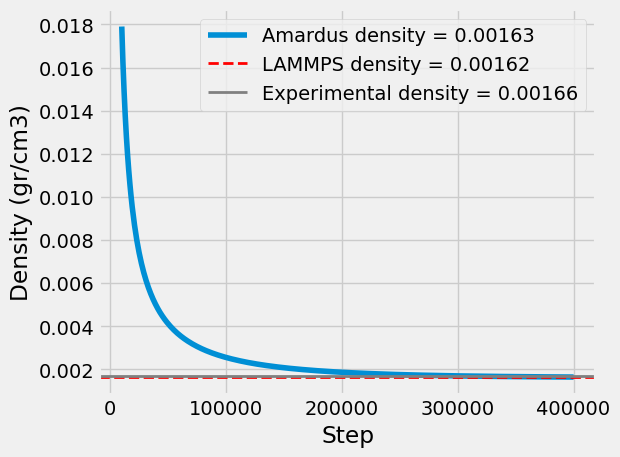

In [11]:
df = pd.read_csv("thermo-ar.csv")

ax = df.plot(
    x="Step",
    y="Density",
    # figsize=(8, 6),
    label=f"Amardus density = {df['Density'][-10:].mean():.5f}",
)

# Experimental melting temperature of Cu (K)
rho_exp = 0.00166
rho_lammps =  0.0016169308

ax.axhline(
    y=rho_lammps,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"LAMMPS density = {rho_lammps:.5f}"
)
ax.axhline(
    y=rho_exp,
    color="gray",
    linestyle="-",
    linewidth=2,
    label=f"Experimental density = {rho_exp:.5f}"
)

ax.set_xlabel("Step")
ax.set_ylabel("Density (gr/cm3)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("ar-density-benchmark.png", dpi=300)
plt.show()

## Simulating mixture of Ar and Ne atoms

Initial configuration      |  After 100ps 
:-------------------------:|:-------------------------:
![](ar-ne-mix.png)  |  ![](ar-ne-mix2.png)

In [7]:
from amardus.integration import LangevinIntegrator
from ase.io import read as read_ase

atoms_ase: AseAtoms = read_ase("argon-neon.xyz")
MaxwellBoltzmannDistribution(
    atoms_ase,
    temperature_K=temperature / unit.kelvin,
    rng=np.random.default_rng(1234),
)
Stationary(atoms_ase)
atom_types_map = {"Ar": 0, "Ne": 1}
atoms = Atoms.from_ase(atoms_ase, atom_types_map)

lennard_jones = LennardJonesPotential(
    cutoff_radius=cutoff,
    params=LennardJonesParams.from_list(
        epsilon=[e * unit.electronvolt for e in [0.01032, 0.00307]],
        sigma=[s * unit.angstrom for s in [3.405, 2.789]],
    ),
)

system = System.create(
    atoms,
    neighbor_cutoff=cutoff,
    neighbor_skin=2.0 * unit.angstrom,
    neighbor_max_atoms=300,
)

langevin = LangevinIntegrator(
    time_step=time_step,
    damping_time=10 * time_step,
    temperature=temperature,
    system_couplings=[
        # barostat,
    ],
)

state = StateReporter(interval=10_000)
xyz = XyzReporter("ar-mixed.xyz", atom_types_map, interval=1000)
csv = CSVReporter("thermo-ar-mixed.csv", interval=1000, ignore_first_steps=1000)

simulation = Simulation(
    system,
    langevin,
    forcefields=[lennard_jones],
    reporters=[state, xyz, csv],
)
print(BANNER)
print(simulation)


      _                            _
     / \   _ __ ___   __ _ _ __ __| |_   _ ___
    / _ \ | '_ ` _ \ / _` | '__/ _` | | | / __|
   / ___ \| | | | | | (_| | | | (_| | |_| \__ \
  /_/   \_\_| |_| |_|\__,_|_|  \__,_|\__,_|___/
           Molecular Dynamics Engine
-------------------------------------------------
Simulation(system=System(num_atoms=864), integrator=LangevinIntegrator(time_step=0.0982269, damping_time=0.9822690000000001, temperature=300.0, system_couplings=[]), forcefields=[LennardJonesPotential(cutoff_radius=7.0)], reporters=[StateReporter(interval=10000), XyzReporter(interval=1000), CSVReporter(interval=1000)], energy_minimizer=GradientDescentEnergyMinimizer(max_steps=10000, force_tolerance=0.001, step_size=0.005))


In [8]:
simulation.step(100_000)

Step     Temp           Press          PotEng         KinEng         TotEng         AvgNgh         Density       
0        309.48533852   99.05526351    -34.87707431   34.56355945    -0.31351486    78.00000000    1.24471987    
10000    310.87809168   4259.65540958  -18.06343478   34.71910319    16.65566841    76.53009259    1.24471987    
20000    289.88411665   4072.07466998  -17.59291636   32.37447999    14.78156363    76.98611111    1.24471987    
30000    289.88502923   3933.12826767  -17.65645510   32.37458191    14.71812680    77.28703704    1.24471987    
40000    311.24446030   4091.50324904  -16.75441998   34.76001952    18.00559953    77.39814815    1.24471987    
50000    308.68951826   4399.01205739  -15.05159185   34.47468163    19.42308979    77.98611111    1.24471987    
60000    300.92193939   4122.03269983  -15.99797767   33.60719248    17.60921481    77.95601852    1.24471987    
70000    308.89978440   3956.69450278  -16.46480660   34.49816432    18.03335771    78.0